In [8]:
import pandas as pd
import numpy as np

import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('train.csv', usecols=['Age', 'Fare', 'Survived'])

In [12]:
df.isnull().sum()

Survived    0
Age         0
Fare        0
dtype: int64

In [9]:
df['Age'].fillna(df['Age'].mean(), inplace=True)

In [10]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [11]:
df.isnull().sum()

Survived    0
Age         0
Fare        0
dtype: int64

In [13]:
X = df.iloc[:, 1:3]
y =df.iloc[: , 0]

In [14]:
X_train, X_test, y_train,y_test = train_test_split(X,y, test_size=0.2, random_state =42)

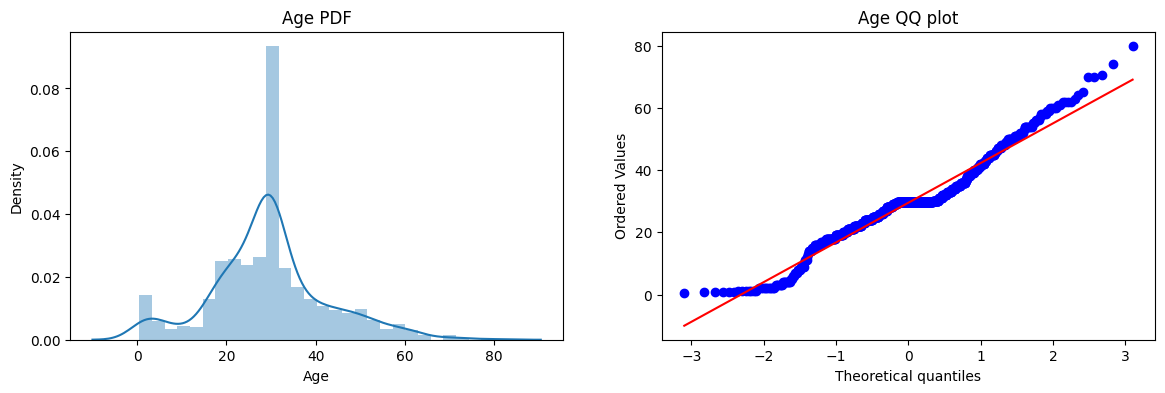

In [17]:
plt.figure(figsize=(14,4))
plt.subplot(121)
sns.distplot(X_train['Age'])
plt.title('Age PDF')

plt.subplot(122)
stats.probplot(X_train['Age'], dist='norm', plot=plt)
plt.title('Age QQ plot')

plt.show()

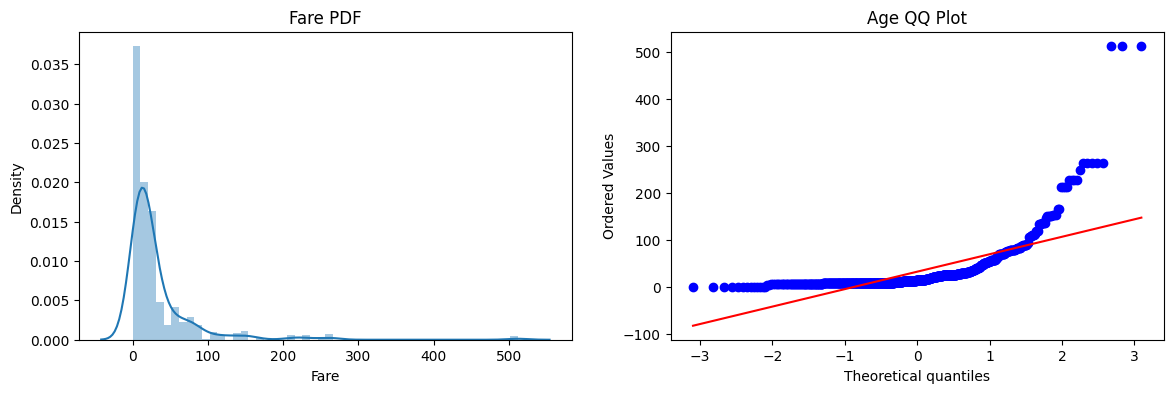

In [20]:
plt.figure(figsize=(14,4))
plt.subplot(121)
sns.distplot(X_train['Fare'])
plt.title('Fare PDF')


plt.subplot(122)
stats.probplot(X_train['Fare'], dist='norm', plot=plt)
plt.title('Age QQ Plot')

plt.show()

In [21]:
clf = LogisticRegression()
clf2= DecisionTreeClassifier()

In [22]:
clf.fit(X_train,y_train)
clf2.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [25]:
y_pred = clf.predict(X_test)
y_pred1 = clf2.predict(X_test)
print('Accuracy LR', accuracy_score(y_test,y_pred))
print('Accuracy DT', accuracy_score(y_test, y_pred1))

Accuracy LR 0.6480446927374302
Accuracy DT 0.664804469273743


In [26]:
trf = FunctionTransformer(func= np.log1p )

In [27]:
X_train_transformed = trf.fit_transform(X_train)
X_test_transformed = trf.fit_transform(X_test)

In [28]:
clf.fit(X_train_transformed, y_train)
clf2.fit(X_train_transformed, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [30]:
y_pred = clf.predict(X_test_transformed)
y_pred1 = clf2.predict(X_test_transformed)
print('Accuracy LR', accuracy_score(y_test, y_pred))
print('Accuracy DT', accuracy_score(y_test, y_pred1))

Accuracy LR 0.6815642458100558
Accuracy DT 0.6815642458100558


In [36]:
X_transformed = trf.fit_transform(X)

In [37]:
print('LR', np.mean(cross_val_score(clf, X_transformed, y , scoring='accuracy', cv=10)))
print('DT', np.mean(cross_val_score(clf2, X_transformed, y, scoring='accuracy', cv=10)))

LR 0.678027465667915
DT 0.6633333333333333


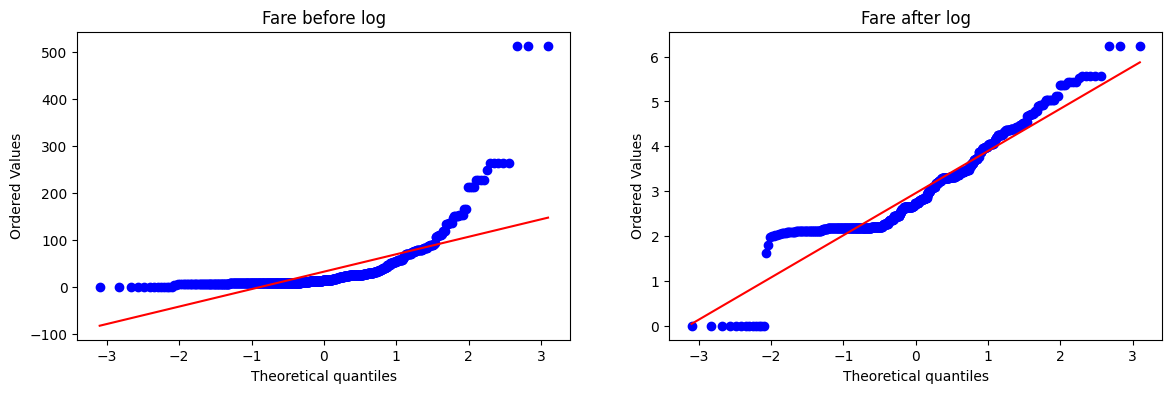

In [38]:
plt.figure(figsize=(14,4))
plt.subplot(121)
stats.probplot(X_train['Fare'], dist='norm', plot=plt)
plt.title('Fare before log')

plt.subplot(122)
stats.probplot(X_train_transformed['Fare'], dist='norm', plot=plt)
plt.title('Fare after log')

plt.show()

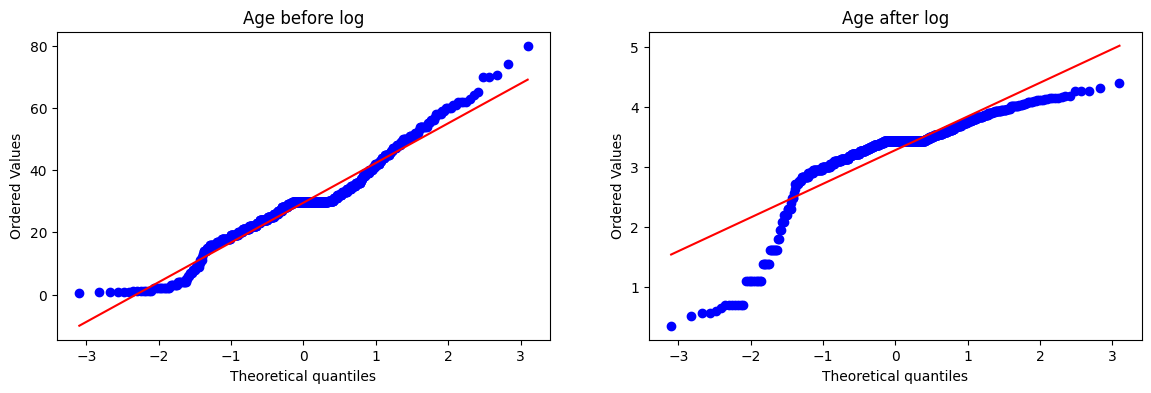

In [40]:
plt.figure(figsize=(14,4))
plt.subplot(121)
stats.probplot(X_train['Age'], dist='norm', plot=plt)
plt.title('Age before log')

plt.subplot(122)
stats.probplot(X_train_transformed['Age'], dist='norm', plot=plt)
plt.title('Age after log')

plt.show()

In [41]:
trf2 = ColumnTransformer([('log', FunctionTransformer(np.log1p),['Fare'])],remainder='passthrough')

In [42]:
X_train_transformed2 = trf2.fit_transform(X_train)
X_test_transformed2 =  trf2.transform(X_test) 

In [44]:
clf.fit(X_train_transformed2, y_train)
clf2.fit(X_train_transformed2, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [45]:
y_pred3 = clf.predict(X_test_transformed2)
y_pred4 = clf2.predict(X_test_transformed2)

In [46]:
print('Accuracy LR', accuracy_score(y_test, y_pred3))
print('Accuracy DT', accuracy_score(y_test, y_pred4))

Accuracy LR 0.6703910614525139
Accuracy DT 0.6927374301675978


In [47]:
X_transformed2= trf2.fit_transform(X)

In [50]:
print('LR', np.mean(cross_val_score(clf, X_transformed2, y, scoring='accuracy', cv =10)))
print('DT', np.mean(cross_val_score(clf2, X_transformed2, y, scoring ='accuracy' , cv = 10)))

LR 0.6712609238451936
DT 0.6599500624219725


In [56]:
def apply_transformer(transformer):
    X = df.iloc[: ,1:3]
    y= df.iloc[: , 0]
    trf3 = ColumnTransformer([('log', FunctionTransformer(transformer),['Fare'])], remainder='passthrough')
    X_trans = trf3.fit_transform(X)
    print('Accuracy', np.mean(cross_val_score(clf, X_trans, y, scoring = 'accuracy', cv =10)))
    plt.figure(figsize=(14,4))
    plt.subplot(121)
    stats.probplot(X['Fare'], dist='norm', plot= plt)
    plt.title('Fare befor transform')

    plt.subplot(122)
    stats.probplot(X_trans[: , 0], dist='norm', plot=plt)
    plt.title('Fare after transform')

    plt.show()
    

Accuracy 0.6589013732833957


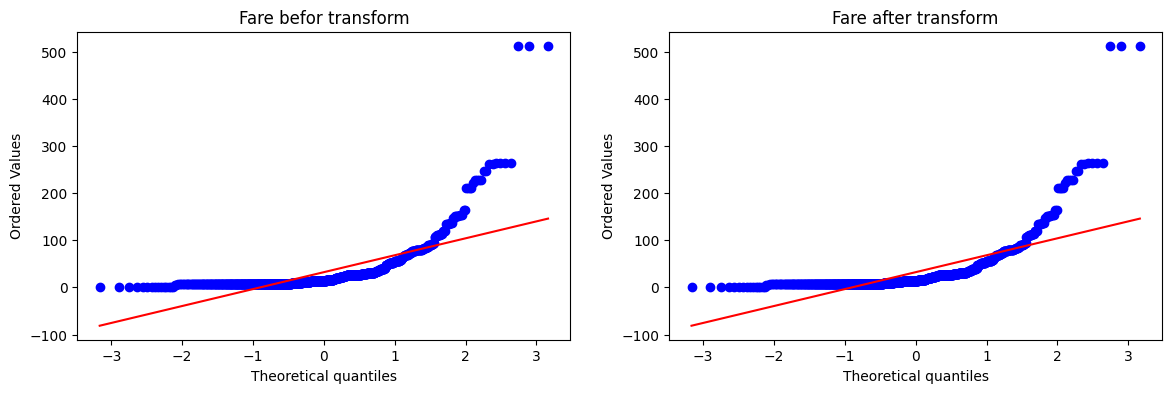

Accuracy 0.6431335830212235


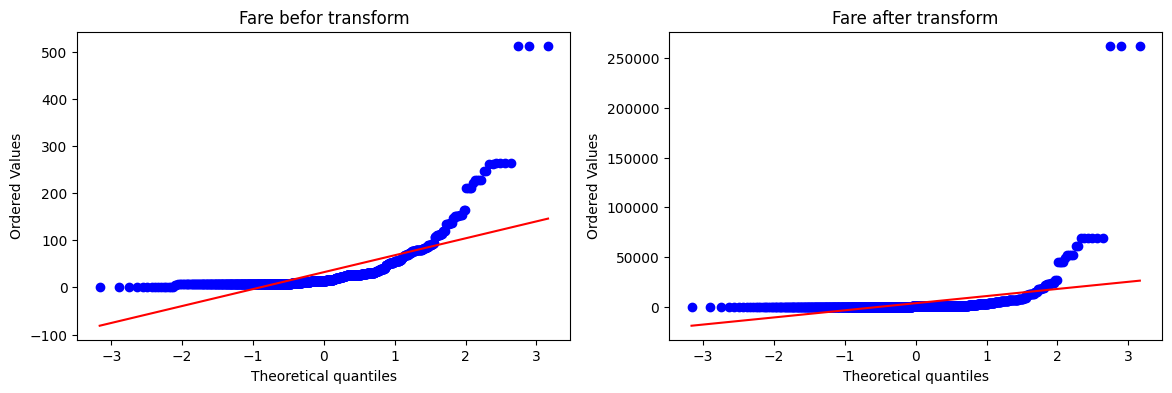

In [60]:
apply_transformer(lambda x:x)

Accuracy 0.6589013732833957


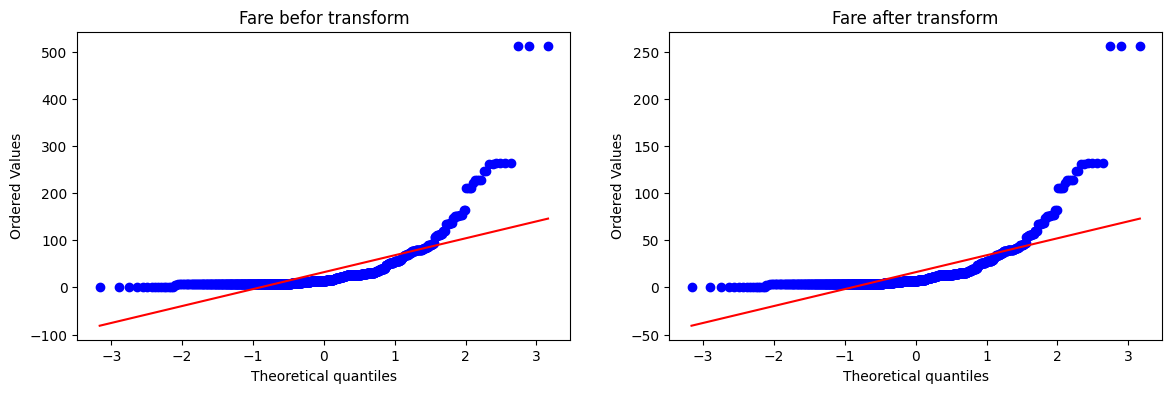

In [61]:
apply_transformer(lambda x:x**1/2)

Accuracy 0.6431335830212235


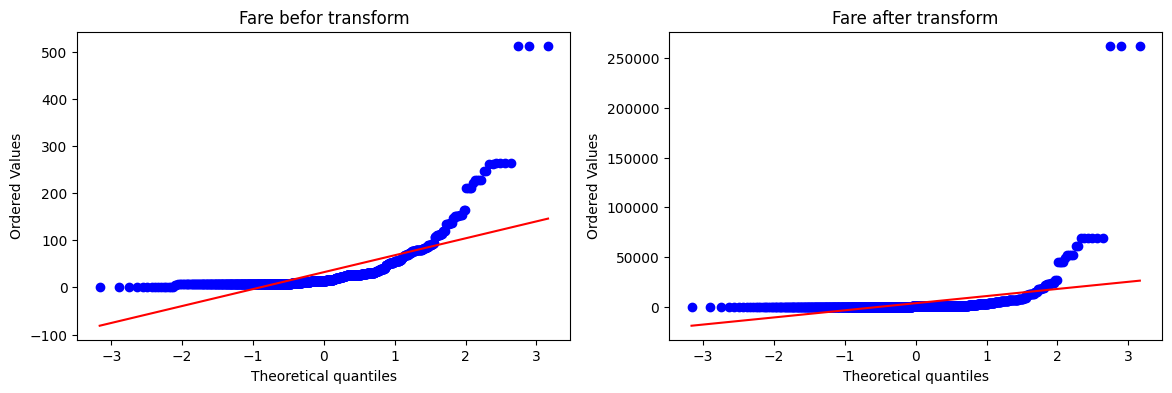

In [62]:
apply_transformer(lambda x:x**2)

Accuracy 0.6195131086142323


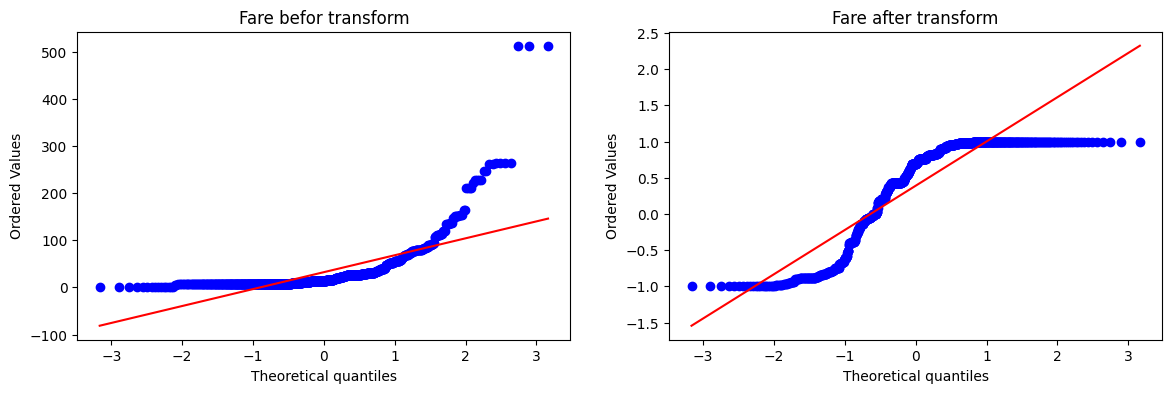

In [63]:
apply_transformer(np.sin)